In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

%matplotlib inline

In [2]:
df = pd.read_csv('amz_uk_price_prediction_dataset.csv')

In [3]:
df.columns

Index(['uid', 'asin', 'title', 'stars', 'reviews', 'price', 'isBestSeller',
       'boughtInLastMonth', 'category'],
      dtype='object')

Part 1: Analyzing Best-Seller Trends Across Product Categories


In [5]:
#Crosstab Analysis:Create a crosstab between the product category and the isBestSeller status.
crosstab_table = pd.crosstab(df['category'],df['isBestSeller'])
crosstab_table

isBestSeller,False,True
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3
...,...,...
Wind Instruments,243,7
Window Treatments,234,5
Women,17559,213


In [8]:
#Are there categories where being a best-seller is more prevalent?



crosstab_table['proportion_bestseller']=crosstab_table[True]/(crosstab_table[False]+crosstab_table[True])
crosstab_table.sort_values('proportion_bestseller',ascending= False).head()

isBestSeller,False,True,proportion_bestseller
category,,,
Grocery,9008,556,0.058135
Smart Home Security & Lighting,98,6,0.057692
Health & Personal Care,9017,552,0.057686
Mobile Phone Accessories,248,11,0.042471
Power & Hand Tools,8353,306,0.035339


In [11]:
#Conduct a Chi-square test to determine if the best-seller distribution is independent of the product category.
from scipy.stats import chi2_contingency
crosstab_result = crosstab_table.drop(columns='proportion_bestseller')
chi2_statistic,chi2_p_value,dof,espected = chi2_contingency(crosstab_result)
chi2_p_value


np.float64(0.0)

In [12]:
from scipy.stats.contingency import association

association(crosstab_result, method="cramer")


0.1222829439760564

Product category is significantly associated with best-seller status (p < 0.001), but the association is weak (Cramér’s V = 0.12). Category alone is not a strong predictor of becoming a best-seller.



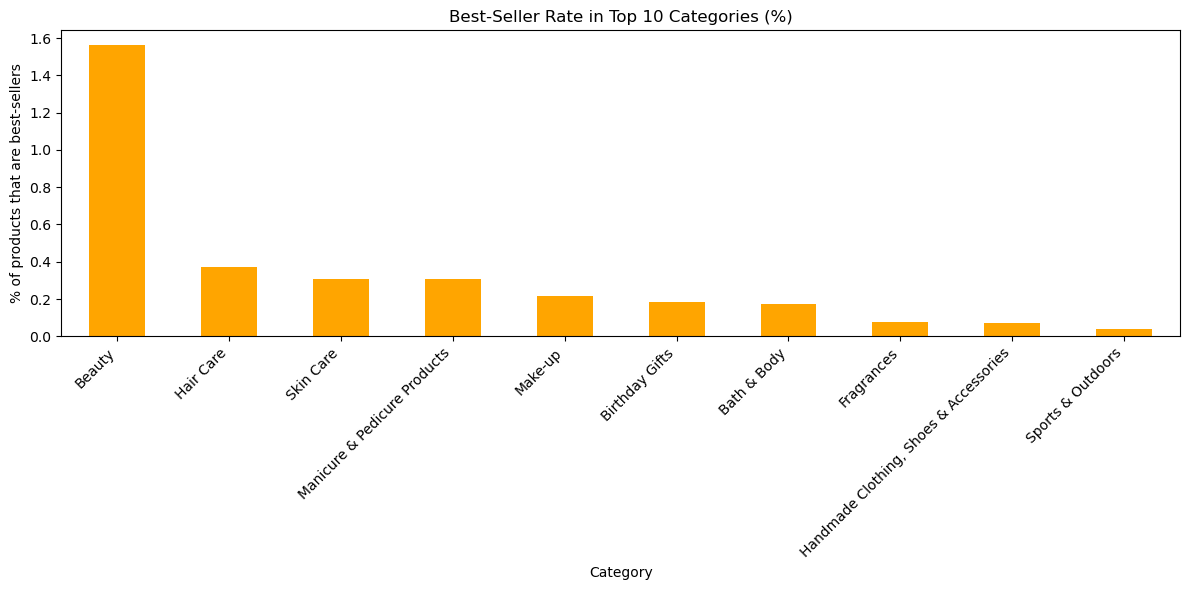

In [17]:
top10_percent[True].sort_values(ascending=False).plot(kind='bar', figsize=(12, 6), color='orange')

plt.title('Best-Seller Rate in Top 10 Categories (%)')
plt.xlabel('Category')
plt.ylabel('% of products that are best-sellers')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

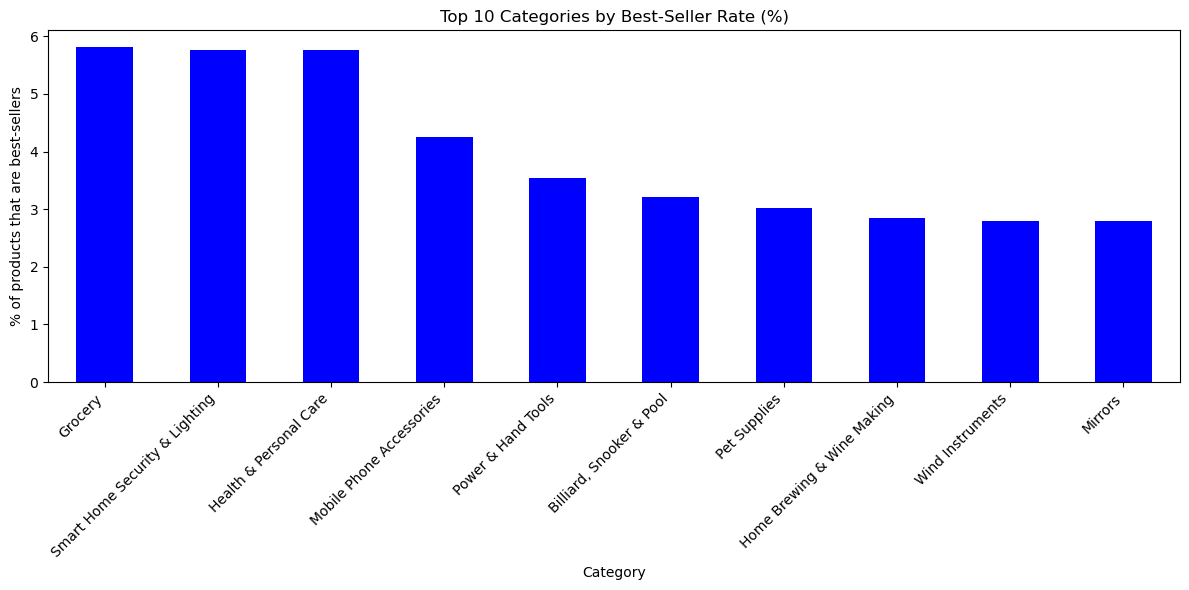

In [19]:
top10_rate = crosstab_table['proportion_bestseller'].sort_values(ascending=False).head(10) * 100

top10_rate.plot(kind='bar', figsize=(12, 6), color='blue')

plt.title('Top 10 Categories by Best-Seller Rate (%)')
plt.xlabel('Category')
plt.ylabel('% of products that are best-sellers')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

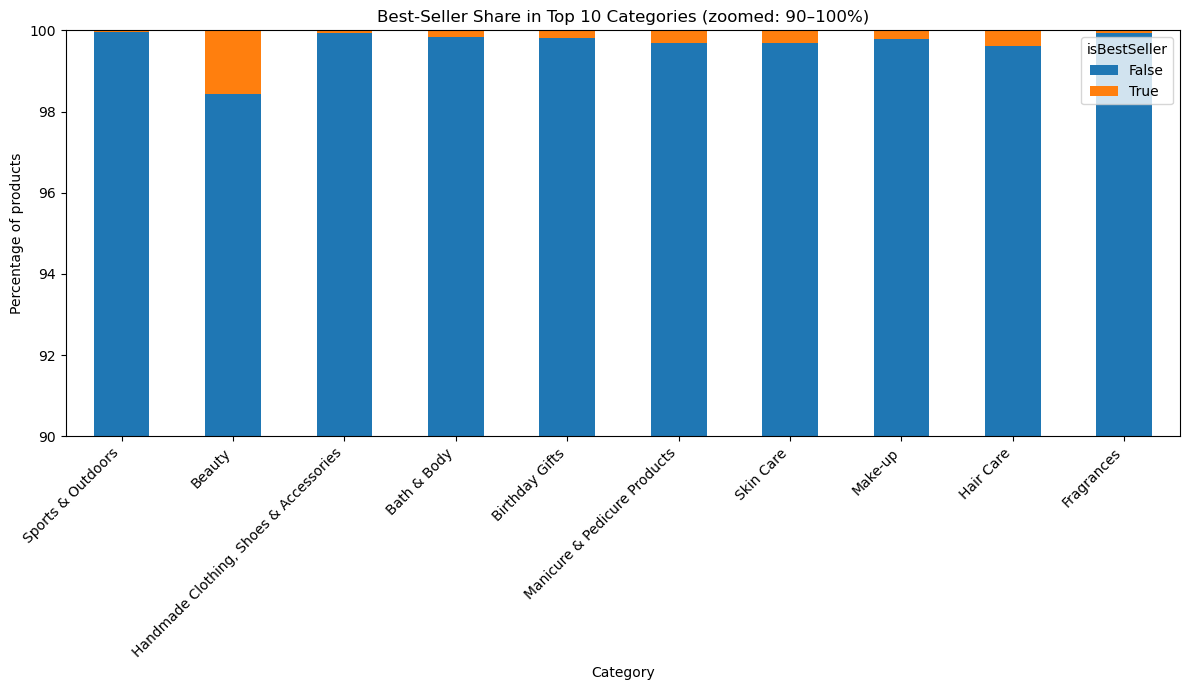

In [20]:
top10_percent.plot(kind='bar', stacked=True, figsize=(12, 7))

plt.ylim(90, 100)
plt.title('Best-Seller Share in Top 10 Categories (zoomed: 90–100%)')
plt.xlabel('Category')
plt.ylabel('Percentage of products')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

The stacked bar chart shows that best-sellers make up only a small share of products in every category. The bars look very similar across categories, which matches the weak association found by Cramér’s V (0.12).

Part 2: Exploring Product Prices and Ratings Across Categories and Brands

In [22]:
Q1 = df['price'].quantile(0.25)
Q3 =df['price'].quantile(0.75)
IQR = Q3-Q1
lower_bound = Q1-1.5*IQR
upper_bound = Q3+1.5*IQR
print(f"Q1: {Q1:.2f}, Q3: {Q3:.2f}, IQR: {IQR:.2f}")
print(f"Lower bound: {lower_bound:.2f}, Upper bound: {upper_bound:.2f}")
df_no_outliers = df[(df['price']>=lower_bound)&(df['price']<=upper_bound)]
print(f"Before: {len(df)} rows")
print(f"After: {len(df_no_outliers)} rows")
print(f"Removed: {len(df) - len(df_no_outliers)} rows")

Q1: 9.99, Q3: 45.99, IQR: 36.00
Lower bound: -44.01, Upper bound: 99.99
Before: 2443651 rows
After: 2115963 rows
Removed: 327688 rows


In [24]:
def remove_outliers(column):
    Q1 = column.quantile(0.25)
    Q3 =column.quantile(0.75)
    IQR = Q3-Q1
    lower_bound = Q1-1.5*IQR
    upper_bound = Q3+1.5*IQR
    print(f"Q1: {Q1:.2f}, Q3: {Q3:.2f}, IQR: {IQR:.2f}")
    print(f"Lower bound: {lower_bound:.2f}, Upper bound: {upper_bound:.2f}")
    df_no_outliers = df[(column>=lower_bound)&(column<=upper_bound)]
    print(f"Before: {len(df)} rows")
    print(f"After: {len(df_no_outliers)} rows")
    print(f"Removed: {len(df) - len(df_no_outliers)} rows")
    return df_no_outliers

In [29]:
df_no_outliers = remove_outliers(df['price'])

Q1: 9.99, Q3: 45.99, IQR: 36.00
Lower bound: -44.01, Upper bound: 99.99
Before: 2443651 rows
After: 2115963 rows
Removed: 327688 rows


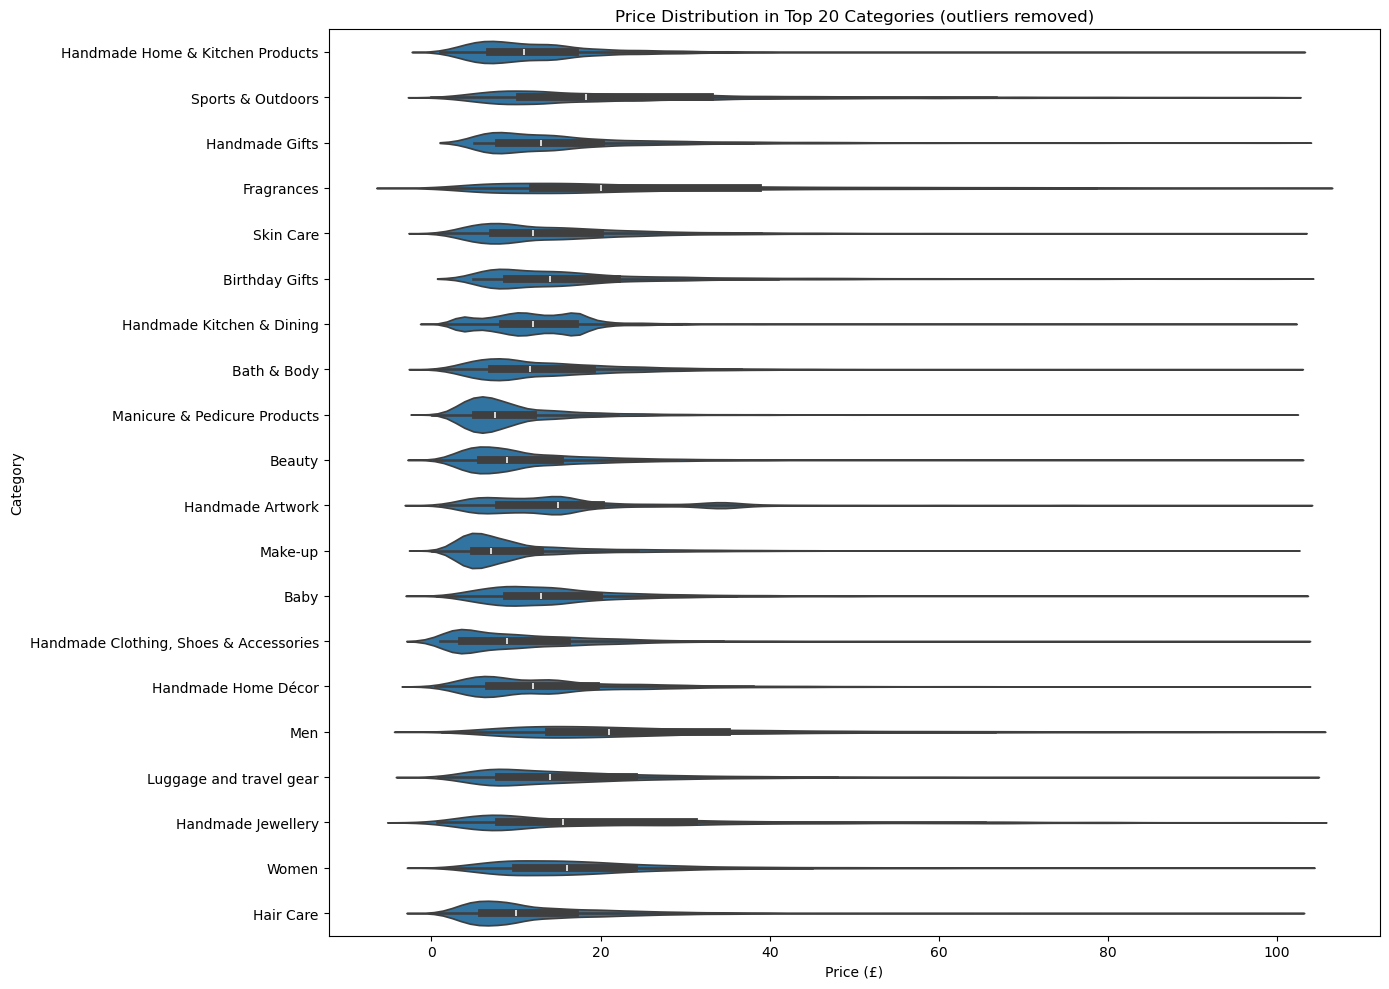

In [32]:
top20= df_no_outliers['category'].value_counts().head(20).index
df_top20 = df_no_outliers[df_no_outliers['category'].isin(top20)]
plt.figure(figsize=(14, 10))
sns.violinplot(data=df_top20, x='price', y='category')

plt.title('Price Distribution in Top 20 Categories (outliers removed)')
plt.xlabel('Price (£)')
plt.ylabel('Category')
plt.tight_layout()
plt.show()

In [34]:
#Which product category tends to have the highest median price? Don't filter here by top categories.
df_no_outliers.groupby('category')['price'].median().sort_values(ascending=False).head(10)

category
Desktop PCs               74.00
Boxing Shoes              69.79
Tablets                   69.00
Graphics Cards            68.54
Motherboards              67.92
Made in Italy Handmade    64.00
Digital Frames            63.90
Streaming Clients         62.68
Golf Shoes                62.39
Ski Helmets               61.33
Name: price, dtype: float64

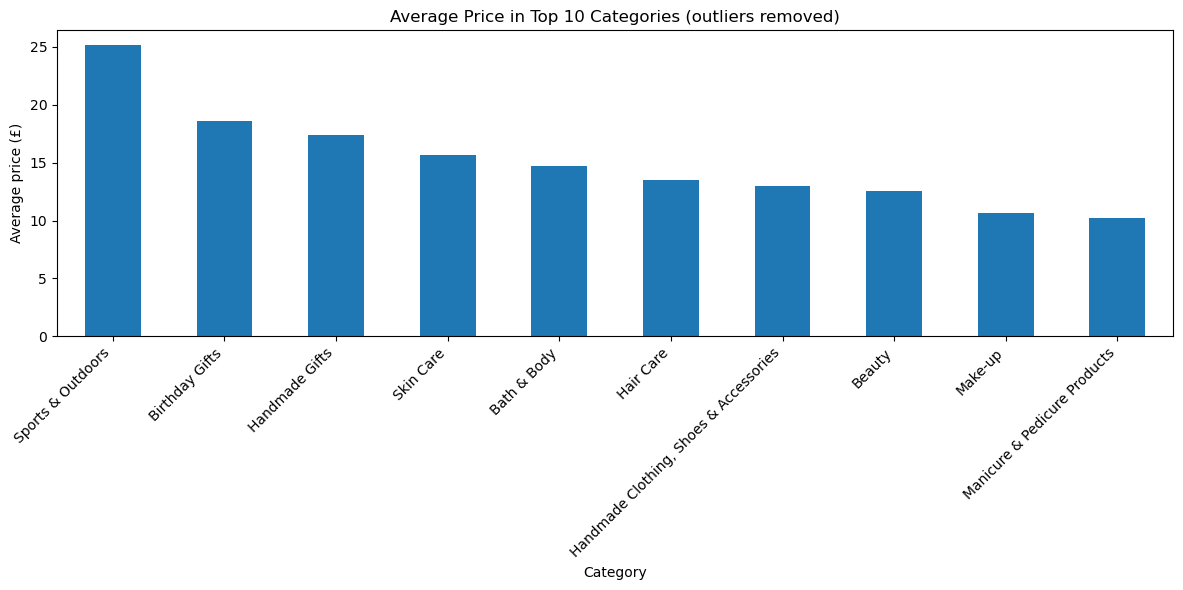

In [37]:
#Create a bar chart comparing the average price of products for the top 10 product categories (based on count).
top10_cat = df_no_outliers['category'].value_counts().head(10).index
df_top10 = df_no_outliers[df_no_outliers['category'].isin(top10_cat)]
avg_price_top10 = df_top10.groupby('category')['price'].mean().sort_values(ascending=False)
avg_price_top10.plot(kind='bar',figsize=(12,6))
plt.title('Average Price in Top 10 Categories (outliers removed)')
plt.xlabel('Category')
plt.ylabel('Average price (£)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

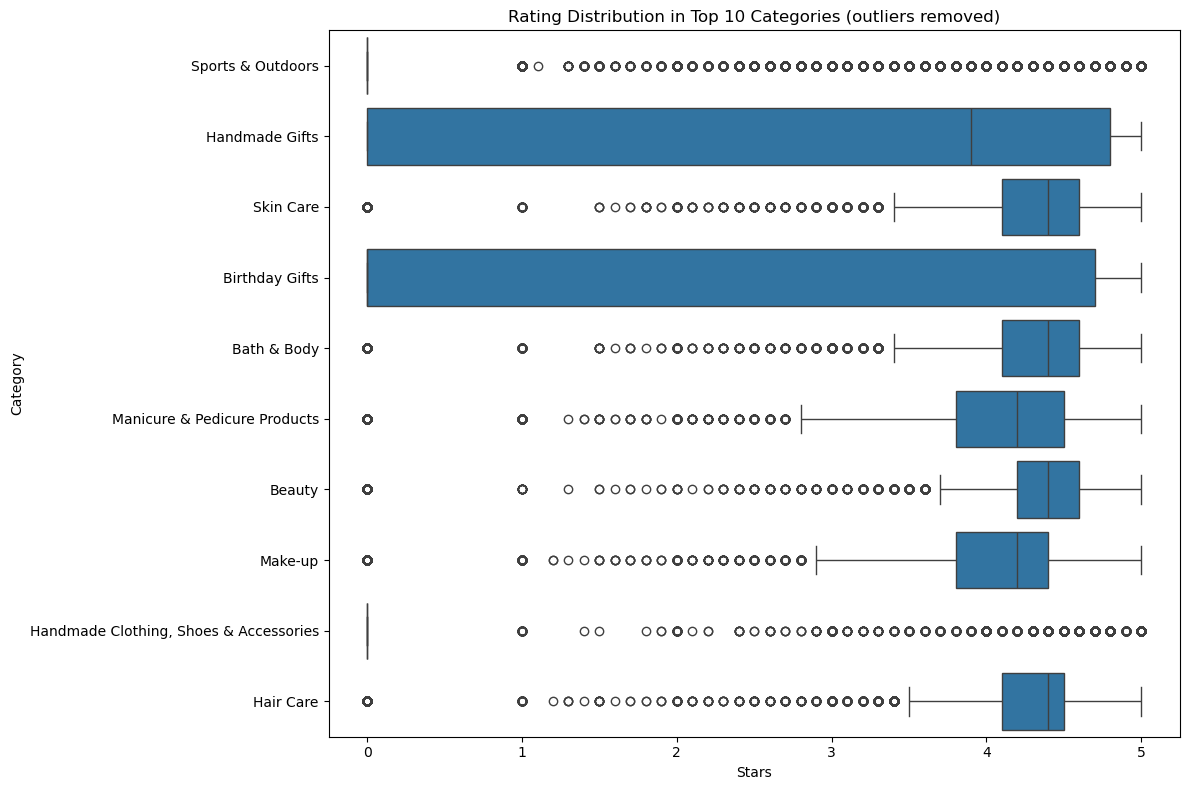

In [42]:
#Visualize the distribution of product ratings based on their category using side-by-side box plots.
#  Filter out the top 10 categories based on count for better visualization.
plt.figure(figsize=(12, 8))
sns.boxplot(data=df_top10, x='stars', y='category')

plt.title('Rating Distribution in Top 10 Categories (outliers removed)')
plt.xlabel('Stars')
plt.ylabel('Category')
plt.tight_layout()
plt.show()

In [43]:
#Which category tends to receive the highest median rating from customers? Don't filter here by top categories.
df_no_outliers.groupby('category')['stars'].median().sort_values(ascending=False).head(10)

category
Computer Memory                 4.7
Building & Construction Toys    4.6
Office Paper Products           4.6
Luxury Food & Drink             4.6
Kids' Play Figures              4.6
Hobbies                         4.6
Beer, Wine & Spirits            4.6
Laptop Accessories              4.6
Cables & Accessories            4.5
CPUs                            4.5
Name: stars, dtype: float64

In [44]:
df_no_outliers[df_no_outliers['stars'] == 0]['reviews'].describe()

count    1001620.0
mean           0.0
std            0.0
min            0.0
25%            0.0
50%            0.0
75%            0.0
max            0.0
Name: reviews, dtype: float64

About 47% of products (after removing price outliers) have 0 stars and 0 reviews, meaning they have not been rated yet. These zeros pull down the median rating of some categories, such as Sports & Outdoors. Among all categories, Computer Memory has the highest median rating (4.7), but the top categories differ by only 0.1–0.2 stars.

In [45]:
df_rated = df_no_outliers[df_no_outliers['stars'] > 0]

Part 3: Investigating the Interplay Between Product Prices and Ratings

In [46]:
#Calculate the correlation coefficient between price and stars.
print(df_no_outliers['price'].corr(df_no_outliers['stars'], method='pearson'))
print(df_no_outliers['price'].corr(df_no_outliers['stars'], method='spearman'))


-0.07767299878181323
-0.06679697280768307


The correlation between price and rating is very weak and negative (Pearson = −0.08, Spearman = −0.07). In practice, price has almost no relationship with customer rating.

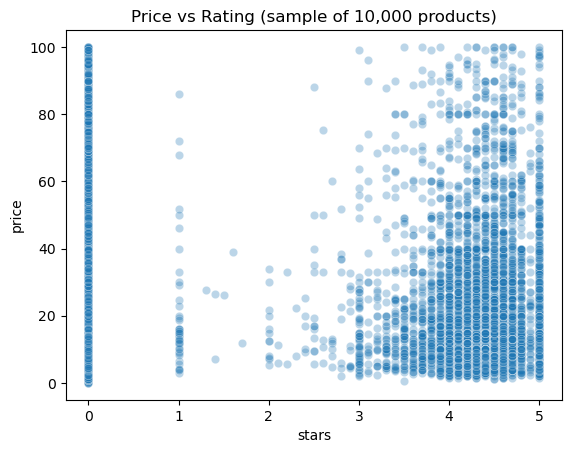

In [47]:
sample = df_no_outliers.sample(10000, random_state=42)

sns.scatterplot(data=sample, x='stars', y='price', alpha=0.3)
plt.title('Price vs Rating (sample of 10,000 products)')
plt.show()

The scatter plot shows no clear relationship between price and rating. Most rated products receive 4–5 stars at every price level, so a higher price does not guarantee a better rating. The vertical line at 0 stars represents unrated products across all prices.

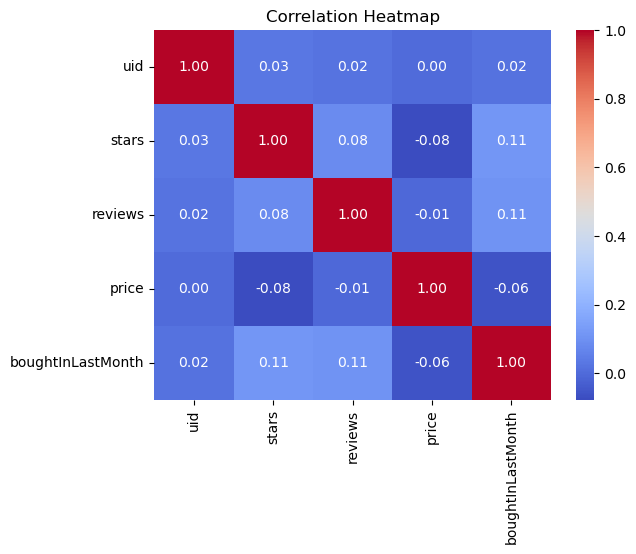

In [48]:
corr_matrix = df_no_outliers.select_dtypes('number').corr()

sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap')
plt.show()

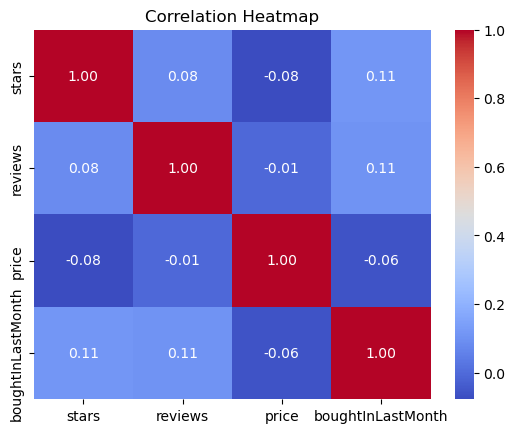

In [49]:
corr_matrix = df_no_outliers.select_dtypes('number').drop(columns='uid').corr()

sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap')
plt.show()

All correlations between numerical variables are very weak (below 0.12). Products with more reviews and higher ratings were bought slightly more often in the last month, while price shows almost no relationship with ratings, reviews, or sales.

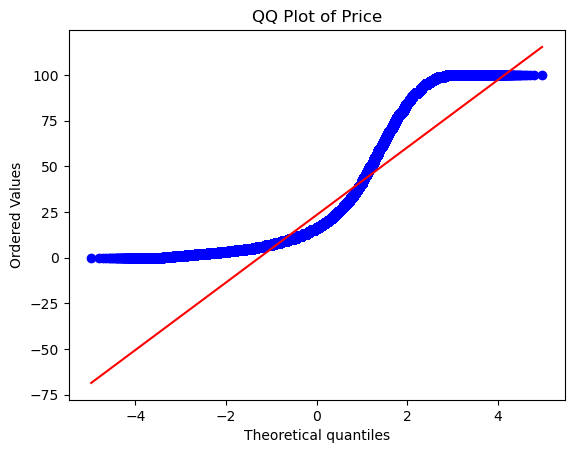

In [50]:
import scipy.stats as stats

stats.probplot(df_no_outliers['price'], dist='norm', plot=plt)
plt.title('QQ Plot of Price')
plt.show()

The QQ plot shows that product prices do not follow a normal distribution. The points curve away from the red line, which confirms that prices are right-skewed: most products are cheap, with fewer expensive ones.